# CivicAI - 04 Stacking meta-classifier

This notebook builds the **final model**: a stacking classifier that combines the three models selected in Phase 5b (XGBoost, Bernoulli Naive Bayes, Random Forest), compares it with each of them on the validation split, scores the **test split once**, and saves the files the API needs.

1. What a stacking classifier is, and how this one is built
2. Choosing the settings of the final estimator
3. Fitting the final model
4. Validation comparison: the stack against its base models and the baselines
5. What the stack learned: its weights
6. Charts
7. Saving the fitted model *(the test section follows after the validation results are committed)*

**Rules followed here**

- **The decision to deploy the stack was made before any result.** It is a course requirement. The validation results below decide only the *settings* of the stack, never *whether* it is deployed. If the stack turns out to be no better than XGBoost alone, that is reported plainly, and the stack is still the deployed model.
- Everything is fitted on the **training split only**. The model is not refitted on train + validation, so the saved file matches the reported scores.
- The **test split is not opened** in sections 1-7. It is read exactly once, in a later section, after these results are saved and committed.

In [1]:
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve

sys.path.insert(0, "..")                 # so that "src" can be imported from the notebooks folder
from src import features as ft
from src import train as tr

FIG_DIR = Path("../reports/figures")
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True,
})
SHORT = {"xgboost": "XGBoost", "naive_bayes": "Bernoulli Naive Bayes", "random_forest": "Random Forest"}

def plot_confusion(ax, row, title):
    counts = np.array([[row["actual0_pred0"], row["actual0_pred1"]], [row["actual1_pred0"], row["actual1_pred1"]]], dtype=float)
    shares = counts / counts.sum(axis=1, keepdims=True)
    ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(counts[i, j]):,}\n{shares[i, j]:.1%}", ha="center", va="center", fontsize=10,
                    color="white" if shares[i, j] > 0.55 else "black")
    ax.set_xticks([0, 1], ["Pred. 0", "Pred. 1"])
    ax.set_yticks([0, 1], ["Actual 0", "Actual 1"])
    ax.set_title(f"{title}\nmacro F1 {row['macro_f1']:.3f}, recall of class 0 {row['recall_0']:.1%}", loc="left", fontsize=9.5)
    ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)

X_train, y_train = tr.load_xy("train", "../data/processed")
X_val, y_val = tr.load_xy("val", "../data/processed")        # test.parquet is not read in this part
best_settings = json.loads(Path("../reports/best_settings.json").read_text())

print(f"Training split  : {len(X_train):,} rows, class 0 share {1 - y_train.mean():.1%}")
print(f"Validation split: {len(X_val):,} rows, class 0 share {1 - y_val.mean():.1%}")
print("Base models and their tuned settings (from reports/best_settings.json, not tuned again):")
for key, name in tr.STACK_MODELS.items():
    print(f"  {name}: {best_settings[name]}")

Training split  : 139,206 rows, class 0 share 17.2%
Validation split: 29,830 rows, class 0 share 16.8%
Base models and their tuned settings (from reports/best_settings.json, not tuned again):
  XGBoost: {'n_estimators': 600, 'learning_rate': 0.05, 'max_depth': 8, 'scale_pos_weight': 0.4556}
  Bernoulli Naive Bayes: {'alpha': 0.1, 'class_prior': None}
  Random Forest: {'n_estimators': 150, 'max_depth': 40, 'min_samples_leaf': 5}


## 1. What a stacking classifier is, and how this one is built

**The idea.** Three different models each look at a request and give a probability that it will be resolved within 7 days. A small fourth model, the **final estimator** (here a Logistic Regression), takes those three probabilities as its inputs and learns how much to trust each one. It outputs the final probability.

```
raw request fields
      |
 [clean]   RequestCleaner: the same cleaning, rare-category and time-feature code as in training
      |
      +--> XGBoost            (its own encoder + model)  --> probability 1 -+
      +--> Bernoulli NB       (0/1 encoder + model)      --> probability 2 -+--> [Logistic Regression] --> final probability
      +--> Random Forest      (its own encoder + model)  --> probability 3 -+
```

The whole thing is **one scikit-learn `Pipeline`** with two steps, `clean` and `stack`. It takes the raw API fields and returns a probability, so the API needs no other code. Each base model is itself a small pipeline of its encoder and its classifier and receives the cleaned table (Naive Bayes uses the all-0/1 encoder `build_binary_encoder`; the others use the shared encoder).

**Out-of-fold predictions.** The final estimator must learn from probabilities that the base models gave for requests they had **not** been trained on. If it learned from probabilities on requests the base models had already seen, it would see them as far more reliable than they are, and over-trust the model that memorises best (the Random Forest). So `StackingClassifier` cuts the training split into 5 folds; for each fold the base models are trained on the other 4 and predict the held-out fold. Every training row then has one honest prediction from each base model, and the final estimator learns from those. After that the base models are refitted on the whole training split for use at prediction time.

**A known compromise in the folds.** Everywhere else in this project the folds respect time (`TimeSeriesSplit`). Inside a stack that is not possible: `StackingClassifier` needs an out-of-fold prediction for **every** training row, but `TimeSeriesSplit` never validates on the first block of rows. So the stack uses **5-fold stratified cross-validation with shuffling** (`StratifiedKFold`, `random_state=42`).

This is a small, known compromise and it stays **inside the training split only**: a base model predicting a training row may have seen requests from slightly later in the same period. The validation and test splits are still entirely in the future of every training row, so they remain honest. The cost is that the out-of-fold predictions may be a little more optimistic than the predictions on the future, which could make the final estimator trust the base models slightly more than it should. Section 2 measures how big that effect is.

**Final estimator.** `LogisticRegression` on the probabilities (`stack_method="predict_proba"`, `passthrough=False`, so it sees only the three probabilities and not the original features). For two classes each base model contributes one probability (that of class 1), so the final estimator has three inputs and one weight for each.

## 2. Choosing the settings of the final estimator

Two settings are tried, 6 combinations in all:

- `class_weight`: none, or `"balanced"` (mistakes on the rare class 0 count about 5 times as much),
- `C` in {0.1, 1, 10}: the strength of regularisation (smaller = simpler).

The final estimator is fitted on the **out-of-fold probabilities of the training split** and scored on the **validation split**, using base models fitted on the whole training split. The setting with the highest **validation macro F1** is kept (ROC-AUC breaks ties).

This is computed directly here so that the 6 combinations do not need 6 full stacks. In section 3 the real `StackingClassifier` is fitted and checked against these numbers.

First, the out-of-fold probabilities, and how they compare with the probabilities on the validation split.

In [2]:
cleaner = ft.RequestCleaner(features=list(ft.FINAL_FEATURES)).fit(X_train)
Xc_train, Xc_val = cleaner.transform(X_train), cleaner.transform(X_val)

start = time.time()
oof_train = tr.out_of_fold_probabilities(best_settings, Xc_train, y_train)       # 5 folds x 3 base models
print(f"Out-of-fold probabilities for {len(oof_train):,} training rows in {time.time() - start:.0f} s")

base_fitted = {key: tr.make_base_pipeline(name, best_settings[name]).fit(Xc_train, y_train) for key, name in tr.STACK_MODELS.items()}
base_val = pd.DataFrame({key: model.predict_proba(Xc_val)[:, 1] for key, model in base_fitted.items()})

rows = []
for key, name in tr.STACK_MODELS.items():
    oof_scores = tr.evaluate_probability(y_train, oof_train[key])
    val_scores = tr.evaluate_probability(y_val, base_val[key])
    rows.append({"base model": name,
                 "ROC-AUC, out-of-fold on train": oof_scores["roc_auc"], "ROC-AUC, validation": val_scores["roc_auc"],
                 "macro F1, out-of-fold on train": oof_scores["macro_f1"], "macro F1, validation": val_scores["macro_f1"]})
oof_table = pd.DataFrame(rows).set_index("base model")
oof_table["AUC gap"] = oof_table["ROC-AUC, out-of-fold on train"] - oof_table["ROC-AUC, validation"]
display(oof_table.style.format("{:.4f}").format("{:+.4f}", subset=["AUC gap"]))
print("Correlation of the three base models' out-of-fold probabilities (what the final estimator sees):")
display(oof_train.rename(columns=SHORT).corr().style.format("{:.3f}"))

Out-of-fold probabilities for 139,206 training rows in 109 s


,"ROC-AUC, out-of-fold on train","ROC-AUC, validation","macro F1, out-of-fold on train","macro F1, validation",AUC gap
base model,,,,,
XGBoost,0.9554,0.9433,0.8369,0.8351,+0.0121
Bernoulli Naive Bayes,0.9441,0.9377,0.8138,0.8093,+0.0064
Random Forest,0.9488,0.9408,0.7999,0.7892,+0.0080


Correlation of the three base models' out-of-fold probabilities (what the final estimator sees):


,XGBoost,Bernoulli Naive Bayes,Random Forest
XGBoost,1.000,0.955,0.963
Bernoulli Naive Bayes,0.955,1.000,0.942
Random Forest,0.963,0.942,1.000


**Reading it.** If the out-of-fold scores were much better than the validation scores, the shuffled folds would be flattering the base models and the final estimator would learn to trust them too much.

The out-of-fold ROC-AUC is higher than the validation ROC-AUC for all three models, by 0.006 (Naive Bayes), 0.008 (Random Forest) and 0.012 (XGBoost). The out-of-fold macro F1 is also higher, by 0.002 to 0.011. So the shuffled folds are a little optimistic, as expected, but the gap is small compared with the differences between the models, and the out-of-fold probabilities are also slightly more correlated with each other (0.94 to 0.96) than the validation ones (0.93 to 0.95). The compromise is therefore unlikely to matter much, although it cannot be ruled out as a small influence on the weights in section 5.

In [3]:
tuning = tr.tune_final_estimator(oof_train, y_train, base_val, y_val)
tuning.insert(0, "chosen", [i == 0 for i in range(len(tuning))])
tuning.to_csv("../reports/stacking_tuning.csv", index=False)

show = ["chosen", "class_weight", "C", "accuracy", "precision_0", "recall_0", "f1_0", "macro_f1", "roc_auc"] + [f"weight_{k}" for k in tr.STACK_MODELS]
print("The 6 settings of the final estimator, best validation macro F1 first:")
display(tuning[show].style.format({c: "{:.4f}" for c in show if c not in ("chosen", "class_weight", "C")}).format({"C": "{:g}"}).hide(axis="index"))

chosen = tuning.iloc[0]
final_settings = {"class_weight": None if chosen["class_weight"] == "none" else chosen["class_weight"], "C": float(chosen["C"])}
best_settings[tr.STACK_FINAL_KEY] = final_settings
Path("../reports/best_settings.json").write_text(json.dumps(best_settings, indent=2), encoding="utf-8")
print(f"Chosen: {final_settings}  (validation macro F1 {chosen['macro_f1']:.4f}, ROC-AUC {chosen['roc_auc']:.4f})")
print("Saved ../reports/stacking_tuning.csv, and the chosen setting in ../reports/best_settings.json")

The 6 settings of the final estimator, best validation macro F1 first:


chosen,class_weight,C,accuracy,precision_0,recall_0,f1_0,macro_f1,roc_auc,weight_xgboost,weight_naive_bayes,weight_random_forest
True,balanced,0.1,0.889641,0.623328,0.865588,0.724749,0.827867,0.942936,4.378315,-1.267406,5.082695
False,balanced,10,0.888569,0.620576,0.864989,0.722676,0.826476,0.942798,4.452206,-1.509218,5.441885
False,balanced,1,0.888401,0.620063,0.865388,0.722468,0.826313,0.942813,4.445710,-1.483875,5.398852
False,none,0.1,0.902883,0.713131,0.705013,0.709049,0.825381,0.943061,5.217739,-1.233486,3.794330
False,none,10,0.902715,0.713706,0.702017,0.707813,0.824728,0.942865,5.558839,-1.577862,4.023276
False,none,1,0.902682,0.713474,0.702217,0.707801,0.824710,0.942887,5.524539,-1.542949,4.000111


Chosen: {'class_weight': 'balanced', 'C': 0.1}  (validation macro F1 0.8279, ROC-AUC 0.9429)
Saved ../reports/stacking_tuning.csv, and the chosen setting in ../reports/best_settings.json


**Reading the table.**

- The six settings differ mainly in **where the stack puts its cut-off**, not in how well it ranks requests. ROC-AUC is almost the same in all six rows (0.9428 to 0.9431).
- With `class_weight="balanced"` the final estimator treats a missed slow request as about 5 times worse than a false alarm. It flags more slow requests (recall of class 0 about 86.5%) at the price of more false alarms (precision about 62%). Without class weights it flags fewer (recall about 70%) but is right more often when it does (precision about 71%).
- The best setting by the rule is **`class_weight="balanced"`, `C=0.1`** (validation macro F1 0.8279). All six macro F1 values lie within 0.004 of each other, and `C` matters very little, so the choice among them is not important.
- Macro F1 gives the two classes equal weight, and class 0 is the class operations staff want to flag, so a setting that flags slow requests generously is consistent with how this project judges models.

## 3. Fitting the final model

The real stack is built with `tr.build_stack` (the function `python -m src.train` also uses) and fitted on the **raw training rows**, so the `clean` step is fitted on the training split as well. Fitting it takes a few minutes: every base model is trained 5 times for the out-of-fold predictions and once more on the whole training split.

Three checks follow, to show that the real stack is what section 2 described:

1. the weights it learned equal the weights from the direct computation,
2. its fitted base models give the same probabilities as the base models fitted separately,
3. its validation scores equal the row chosen in the table above.

In [4]:
stack_model = tr.build_stack(best_settings, final_settings)
fit_seconds = tr.fit_timed(stack_model, X_train, y_train)
print(f"Stack fitted on the training split in {fit_seconds:.0f} s")
display(stack_model)

# Check 1: weights
weights, intercept = tr.stack_weights(stack_model)
direct = tr.make_final_estimator(final_settings).fit(oof_train, y_train)
print(f"Check 1  largest difference between the stack's weights and the direct computation: "
      f"{np.abs(weights.values - direct.coef_[0]).max():.2e}  (intercept {abs(intercept - direct.intercept_[0]):.2e})")

# Check 2: base models
named = stack_model["stack"].named_estimators_
for key in tr.STACK_MODELS:
    difference = np.abs(named[key].predict_proba(Xc_val)[:, 1] - base_val[key].values).max()
    print(f"Check 2  {SHORT[key]:22s} largest difference in validation probabilities: {difference:.2e}")

# Check 3: scores
stack_scores, stack_val_proba = tr.evaluate(stack_model, X_val, y_val)
print(f"Check 3  stack validation macro F1 {stack_scores['macro_f1']:.4f} (table above: {chosen['macro_f1']:.4f}), "
      f"ROC-AUC {stack_scores['roc_auc']:.4f} (table above: {chosen['roc_auc']:.4f})")
assert abs(stack_scores["macro_f1"] - chosen["macro_f1"]) < 1e-9 and abs(stack_scores["roc_auc"] - chosen["roc_auc"]) < 1e-9

Stack fitted on the training split in 111 s


,steps,"[('clean', ...), ('stack', ...)]"
,transform_input,None
,memory,None
,verbose,False
,features,"['complaint_type', 'descriptor', ...]"
,estimators,"[('xgboost', ...), ('naive_bayes', ...), ...]"
,final_estimator,LogisticRegre...ndom_state=42)
,cv,StratifiedKFo... shuffle=True)
,stack_method,'predict_proba'
,n_jobs,None
,passthrough,False


Check 1  largest difference between the stack's weights and the direct computation: 6.31e-14  (intercept 2.04e-14)
Check 2  XGBoost                largest difference in validation probabilities: 0.00e+00


Check 2  Bernoulli Naive Bayes  largest difference in validation probabilities: 0.00e+00


Check 2  Random Forest          largest difference in validation probabilities: 4.44e-16


Check 3  stack validation macro F1 0.8279 (table above: 0.8279), ROC-AUC 0.9429 (table above: 0.9429)


## 4. Validation comparison

The stack is compared, on the validation split, with:

- each of its **three base models** (fitted on the training split inside the stack),
- the **simple average** of the three base models' probabilities, with no learning,
- **XGBoost alone**, the best single model of Phase 5. It is also one of the stack's base models, so it is the fair yardstick: *what does the stack add over its best member?* It is fitted again separately here as a pipeline of its own, to confirm it gives the same answers as the copy inside the stack,
- the two **baselines** (complaint type only; majority class).

Same metrics as before. Class 0, "not resolved within 7 days", is the class operations staff want to flag, so its precision, recall and F1 are highlighted.

In [5]:
xgb_alone = tr.make_model("XGBoost", best_settings["XGBoost"])
tr.fit_timed(xgb_alone, X_train, y_train)
baselines = tr.make_baselines()
for model in baselines.values():
    tr.fit_timed(model, X_train, y_train)

difference = np.abs(xgb_alone.predict_proba(X_val)[:, 1] - base_val["xgboost"].values).max()
print(f"XGBoost fitted alone vs the copy inside the stack: largest difference in validation probabilities {difference:.2e}")

val_probability = {
    "Stack": stack_val_proba,
    "XGBoost": xgb_alone.predict_proba(X_val)[:, 1],
    "Random Forest": base_val["random_forest"].values,
    "Bernoulli Naive Bayes": base_val["naive_bayes"].values,
    "Simple average of the 3": base_val.mean(axis=1).values,
    "Baseline: complaint type only": baselines["Baseline: complaint type only"].predict_proba(X_val)[:, 1],
    "Baseline: majority class": baselines["Baseline: majority class"].predict_proba(X_val)[:, 1],
}
roles = {"Stack": "final model", "XGBoost": "base model, best single model", "Random Forest": "base model",
         "Bernoulli Naive Bayes": "base model", "Simple average of the 3": "no learning",
         "Baseline: complaint type only": "baseline", "Baseline: majority class": "baseline"}
validation = pd.DataFrame({name: tr.evaluate_probability(y_val, p) for name, p in val_probability.items()}).T
validation.insert(0, "role", pd.Series(roles))
validation.index.name = "model"
validation.to_csv("../reports/stacking_validation.csv")
print("Saved ../reports/stacking_validation.csv")

CLASS0 = ["precision_0", "recall_0", "f1_0"]
columns = ["accuracy"] + CLASS0 + ["precision_1", "recall_1", "f1_1", "macro_f1", "roc_auc"]
print(f"Validation split, {len(y_val):,} requests ({int((y_val == 0).sum()):,} in class 0). Class 0 is highlighted.")
display(validation[columns].astype(float).style.format("{:.4f}")
        .set_properties(subset=CLASS0, **{"background-color": "#fdebd8", "color": "black", "font-weight": "bold"})
        .highlight_max(subset=["macro_f1", "roc_auc"], props="text-decoration: underline; font-weight: bold"))

print("Confusion matrix counts")
display(validation[["actual0_pred0", "actual0_pred1", "actual1_pred0", "actual1_pred1"]].astype(int)
        .rename(columns={"actual0_pred0": "slow, flagged (correct)", "actual0_pred1": "slow, missed",
                         "actual1_pred0": "fast, flagged by mistake", "actual1_pred1": "fast, not flagged (correct)"})
        .style.format("{:,}"))

XGBoost fitted alone vs the copy inside the stack: largest difference in validation probabilities 0.00e+00


Saved ../reports/stacking_validation.csv
Validation split, 29,830 requests (5,007 in class 0). Class 0 is highlighted.


,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1,roc_auc
model,,,,,,,,,
Stack,0.8896,0.6233,0.8656,0.7247,0.9706,0.8945,0.9310,0.8279,0.9429
XGBoost,0.8994,0.6620,0.8189,0.7321,0.9616,0.9157,0.9381,0.8351,0.9433
Random Forest,0.8542,0.5398,0.8906,0.6721,0.9746,0.8468,0.9062,0.7892,0.9408
Bernoulli Naive Bayes,0.8762,0.5918,0.8460,0.6964,0.9660,0.8823,0.9222,0.8093,0.9377
Simple average of the 3,0.8889,0.6243,0.8496,0.7197,0.9673,0.8969,0.9307,0.8252,0.9420
Baseline: complaint type only,0.8915,0.6866,0.6499,0.6678,0.9301,0.9402,0.9351,0.8014,0.9377
Baseline: majority class,0.8321,0.0000,0.0000,0.0000,0.8321,1.0000,0.9084,0.4542,0.5000


Confusion matrix counts


,"slow, flagged (correct)","slow, missed","fast, flagged by mistake","fast, not flagged (correct)"
model,,,,
Stack,"4,334",673,"2,619","22,204"
XGBoost,"4,100",907,"2,093","22,730"
Random Forest,"4,459",548,"3,802","21,021"
Bernoulli Naive Bayes,"4,236",771,"2,922","21,901"
Simple average of the 3,"4,254",753,"2,560","22,263"
Baseline: complaint type only,"3,254","1,753","1,485","23,338"
Baseline: majority class,0,"5,007",0,"24,823"


### What does the stack add over XGBoost alone?

The difference is shown in **percentage points** (the stack minus XGBoost). A positive number means the stack is better, except for the two confusion counts, where fewer is better.

The last two columns are a rough guide to whether a difference is real: 1,000 random resamples of the validation requests (the same requests for both models, each time) give a 95% range for the difference in macro F1 and in ROC-AUC. These ranges are likely **too narrow**, because requests filed close together in time are not independent, so treat them as the best case.

In [6]:
from sklearn.metrics import f1_score, roc_auc_score

stack_row, xgb_row = validation.loc["Stack"], validation.loc["XGBoost"]
metrics = ["accuracy", "precision_0", "recall_0", "f1_0", "macro_f1", "roc_auc"]
gain = pd.DataFrame({"stack": stack_row[metrics].astype(float), "XGBoost alone": xgb_row[metrics].astype(float)})
gain["stack minus XGBoost (points)"] = (gain["stack"] - gain["XGBoost alone"]) * 100

# Paired bootstrap on the validation rows
rng = np.random.default_rng(42)
y_array = y_val.to_numpy()
p_stack, p_xgb = val_probability["Stack"], val_probability["XGBoost"]
diffs = {"macro_f1": [], "roc_auc": []}
for _ in range(1000):
    pick = rng.integers(0, len(y_array), len(y_array))
    yy = y_array[pick]
    diffs["macro_f1"].append(f1_score(yy, p_stack[pick] > 0.5, average="macro") - f1_score(yy, p_xgb[pick] > 0.5, average="macro"))
    diffs["roc_auc"].append(roc_auc_score(yy, p_stack[pick]) - roc_auc_score(yy, p_xgb[pick]))
for metric, values in diffs.items():
    low, high = np.percentile(values, [2.5, 97.5]) * 100
    gain.loc[metric, "95% range (points)"] = f"{low:+.2f} to {high:+.2f}"
display(gain.style.format({"stack": "{:.4f}", "XGBoost alone": "{:.4f}", "stack minus XGBoost (points)": "{:+.2f}"}, na_rep=""))

fewer = validation[["actual0_pred1", "actual1_pred0"]].astype(int)
print(f"Slow requests missed        : stack {fewer.loc['Stack', 'actual0_pred1']:,}, XGBoost {fewer.loc['XGBoost', 'actual0_pred1']:,}")
print(f"Fast requests flagged wrongly: stack {fewer.loc['Stack', 'actual1_pred0']:,}, XGBoost {fewer.loc['XGBoost', 'actual1_pred0']:,}")

,stack,XGBoost alone,stack minus XGBoost (points),95% range (points)
accuracy,0.8896,0.8994,-0.98,
precision_0,0.6233,0.6620,-3.87,
recall_0,0.8656,0.8189,+4.67,
f1_0,0.7247,0.7321,-0.74,
macro_f1,0.8279,0.8351,-0.73,-1.00 to -0.45
roc_auc,0.9429,0.9433,-0.04,-0.09 to +0.02


Slow requests missed        : stack 673, XGBoost 907
Fast requests flagged wrongly: stack 2,619, XGBoost 2,093


**Plainly: on the validation split the stack does not beat XGBoost alone.**

- **Macro F1: the stack is 0.73 points lower** (0.828 against 0.835). The 95% range, -1.00 to -0.45 points, does not include zero, so this is probably a real difference rather than noise, and the range is if anything too narrow.
- **ROC-AUC: no difference.** 0.9429 against 0.9433, a difference of 0.04 points; the range (-0.09 to +0.02) includes zero. The two rank requests equally well.
- **The difference is where the cut-off sits, not how requests are ranked.** The stack flags more slow requests (recall of class 0 86.6% against 81.9%, +4.7 points; 673 slow requests missed against 907) but raises more false alarms (2,619 fast requests flagged against 2,093; precision of class 0 62.3% against 66.2%, -3.9 points). Accuracy is 1.0 point lower. At the cut-off of 0.5, macro F1 happens to favour XGBoost's more even mix of the two kinds of mistake. The stack with no class weight in its final estimator (section 2) sits at the other end (recall about 70%, precision about 71%) and scores 0.825, so neither version of the stack catches up with XGBoost at this cut-off.
- **Against the other models** the stack is better than Random Forest (+3.9 points of macro F1), Naive Bayes (+1.9), the simple average (+0.3) and the complaint-type baseline (+2.7), and below XGBoost (-0.7). The simple average, which learns nothing, comes within 0.3 points of the stack.
- **Why there is little to gain.** The three base models are highly correlated (0.925 to 0.951 on validation), so there is little new information to combine. Phase 5b showed that at least one of the three is right for only 1.5 points more requests than XGBoost alone, which is the most any combination could gain. XGBoost is also clearly the strongest of the three (macro F1 0.835 against 0.809 and 0.789). The stack does what a stack can do on this data: it matches XGBoost's ranking and moves the cut-off. It does not improve the ranking.

**What this means for the project.** As agreed before the results, the stack is still the deployed model: its validation results only chose its settings. For the report, the honest statement is that the stacking classifier was built as required and, on the validation split, did not improve on its best member. XGBoost alone remains the fair yardstick, and it is kept in every table for that reason.

## 5. What the stack learned: its weights

The final estimator is a Logistic Regression, so what it learned is easy to read: one **weight per base model**, applied to that model's probability, plus a constant (the intercept). The stack's final probability is `1 / (1 + exp(-(intercept + w1 * p1 + w2 * p2 + w3 * p3)))`.

- A **larger weight** means the stack moves further when that model changes its mind.
- The weights are not shares that add up to 1, and they are not directly comparable across models: Naive Bayes gives probabilities close to 0 or 1, so a small weight on it still has a large effect. The third column therefore multiplies each weight by how much that model's probability varies on the validation split (its standard deviation), which is a fairer measure of how much each model moves the result.

,weight,std of its probability (validation),weight x std,share of total |weight x std|
XGBoost,+4.378,0.305,+1.335,37.9%
Bernoulli Naive Bayes,-1.267,0.395,-0.500,14.2%
Random Forest,+5.083,0.332,+1.690,47.9%


Intercept: -4.150    final estimator settings: {'class_weight': 'balanced', 'C': 0.1}


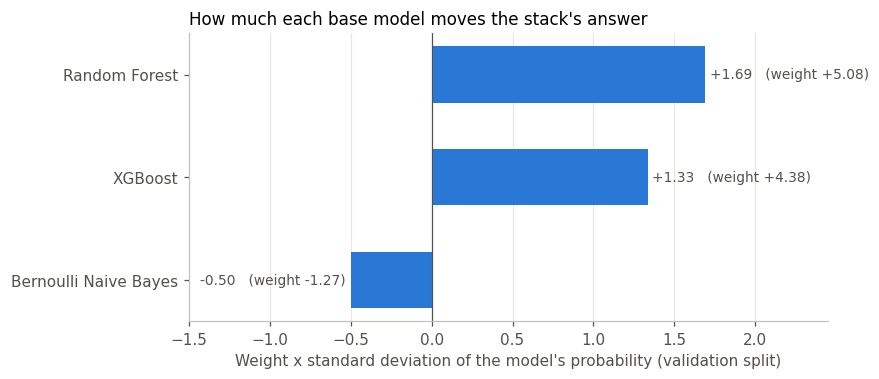

In [7]:
weights, intercept = tr.stack_weights(stack_model)
spread = base_val.std()
weights_table = pd.DataFrame({"weight": weights.values, "std of its probability (validation)": spread.values,
                              "weight x std": weights.values * spread.values}, index=[SHORT[k] for k in weights.index])
weights_table["share of total |weight x std|"] = weights_table["weight x std"].abs() / weights_table["weight x std"].abs().sum()
display(weights_table.style.format({"weight": "{:+.3f}", "std of its probability (validation)": "{:.3f}",
                                    "weight x std": "{:+.3f}", "share of total |weight x std|": "{:.1%}"}))
print(f"Intercept: {intercept:+.3f}    final estimator settings: {final_settings}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot = weights_table["weight x std"].sort_values()
bars = ax.barh(plot.index, plot.values, color=BLUE, height=0.55)
ax.bar_label(bars, labels=[f"{w:+.2f}   (weight {weights_table.loc[n, 'weight']:+.2f})" for n, w in plot.items()], color=INK, fontsize=9, padding=3)
ax.set_xlim(min(0, plot.min()) - 1.0, plot.max() * 1.45)
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlabel("Weight x standard deviation of the model's probability (validation split)")
ax.set_title("How much each base model moves the stack's answer", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "06_stack_weights.png")
plt.show()

**Reading the weights.**

- XGBoost (+4.38) and Random Forest (+5.08) get large positive weights. **Bernoulli Naive Bayes gets a negative weight (-1.27).** That is not an error. Naive Bayes is correlated with the other two (0.94 to 0.96 out-of-fold) but more extreme, so the stack uses it as a *correction*: when Naive Bayes is more optimistic than the other two, the stack lowers its answer a little.
- After allowing for how much each model's probability varies (third column), the pull is **Random Forest 48%, XGBoost 38%, Naive Bayes 14%**. The stack leans on the Random Forest more than on XGBoost even though XGBoost is the better model on its own. Because the three probabilities are so strongly correlated, a Logistic Regression can split the credit among them in many nearly equivalent ways, so the individual weights are **not a reliable ranking of the models**. What matters is the combined answer.
- The intercept (-4.15) balances the weights: if all three models said 0 the stack would answer about 2%, and if all three said 1 about 98%.

## 6. Charts

### Confusion matrices (validation split)

Rows are what really happened, columns what the model predicted. The percentages are shares of each row, so the top-left cell is the **recall of class 0**: the share of slow requests the model flagged.

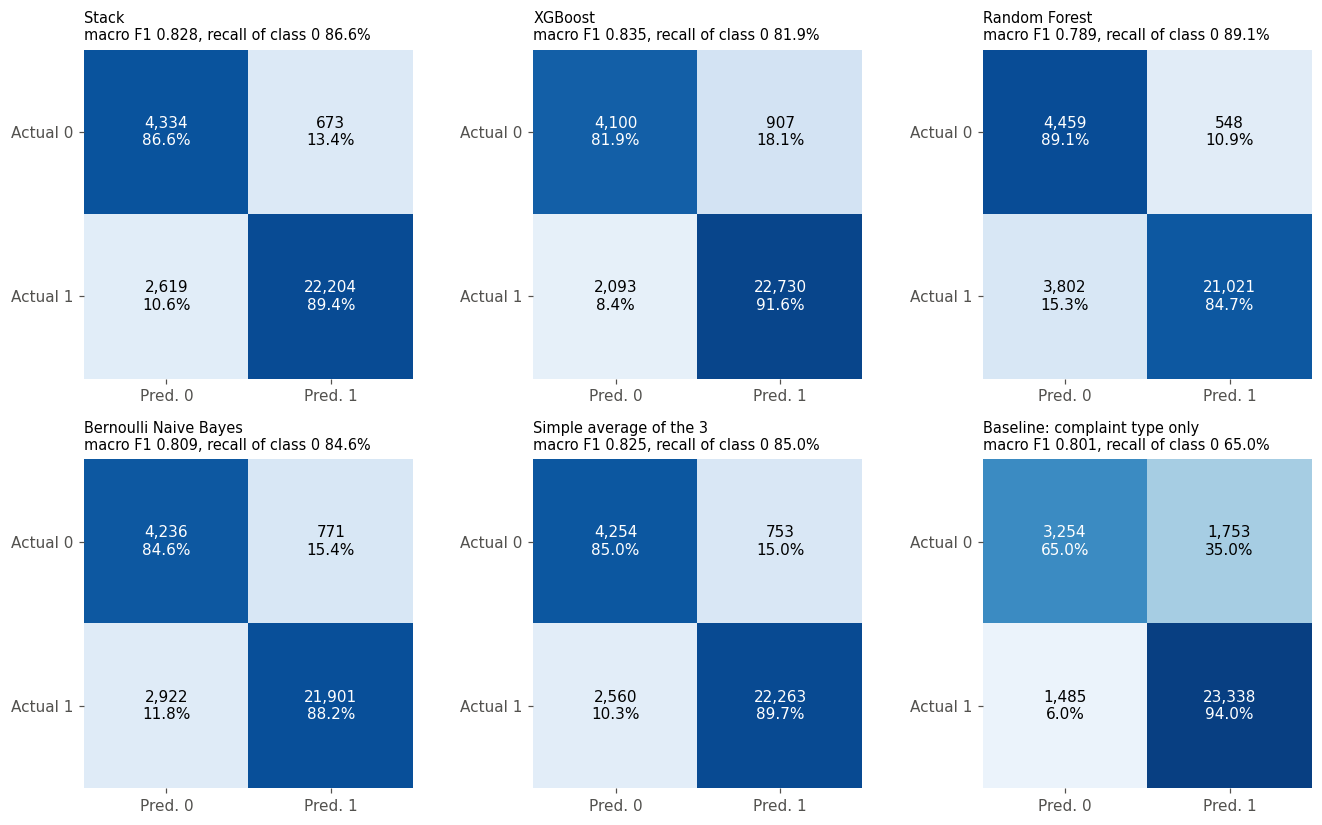

In [8]:
panels = ["Stack", "XGBoost", "Random Forest", "Bernoulli Naive Bayes", "Simple average of the 3", "Baseline: complaint type only"]
fig, axes = plt.subplots(2, 3, figsize=(12.5, 7.6))
for ax, name in zip(axes.ravel(), panels):
    plot_confusion(ax, validation.loc[name].drop("role").astype(float), name)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_validation_confusion_matrices.png")
plt.show()

### ROC curves and the main scores (validation split)

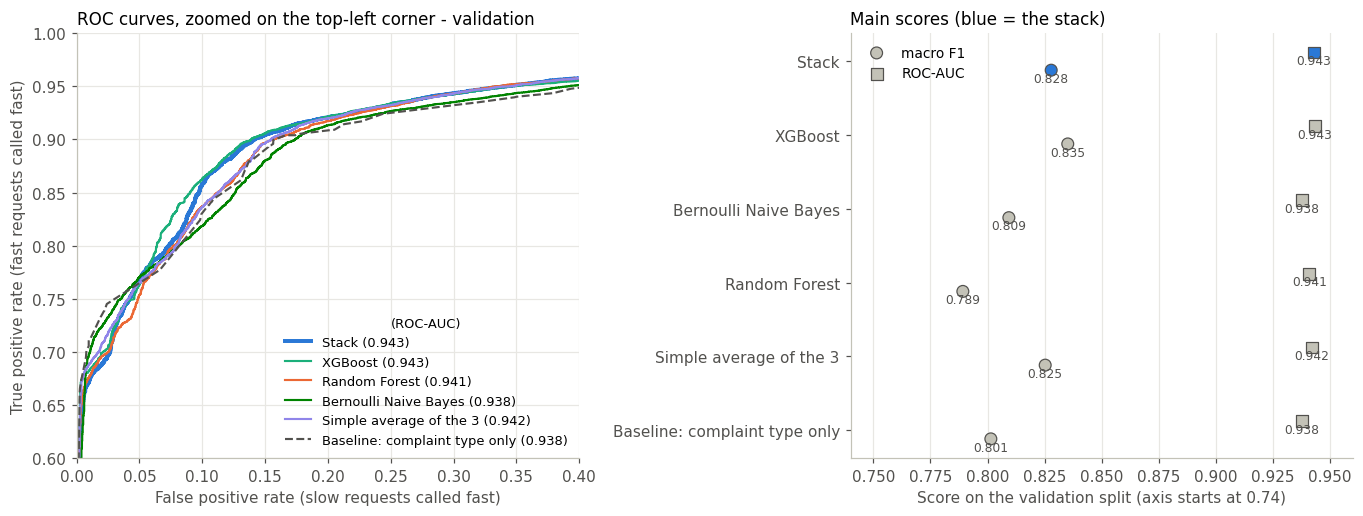

In [9]:
colors = {"Stack": BLUE, "XGBoost": AQUA, "Random Forest": ORANGE, "Bernoulli Naive Bayes": "#008300",
          "Simple average of the 3": "#9085e9", "Baseline: complaint type only": INK}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for name, color in colors.items():
    fpr, tpr, _ = roc_curve(y_val, val_probability[name])
    axes[0].plot(fpr, tpr, color=color, linewidth=2.6 if name == "Stack" else 1.4, linestyle="--" if name.startswith("Baseline") else "-",
                 label=f"{name} ({validation.loc[name, 'roc_auc']:.3f})")
axes[0].set_xlim(0, 0.4)
axes[0].set_ylim(0.6, 1.0)
axes[0].set_xlabel("False positive rate (slow requests called fast)")
axes[0].set_ylabel("True positive rate (fast requests called fast)")
axes[0].set_title("ROC curves, zoomed on the top-left corner - validation", loc="left", fontsize=11)
axes[0].legend(loc="lower right", frameon=False, fontsize=8.5, title="(ROC-AUC)", title_fontsize=8.5)

order = ["Baseline: complaint type only", "Simple average of the 3", "Random Forest", "Bernoulli Naive Bayes", "XGBoost", "Stack"]
positions = np.arange(len(order))
for score, marker, offset in [("macro_f1", "o", -0.12), ("roc_auc", "s", 0.12)]:
    axes[1].scatter([validation.loc[n, score] for n in order], positions + offset,
                    color=[BLUE if n == "Stack" else GREY for n in order], marker=marker, s=60, edgecolor=INK, linewidth=0.8, zorder=3,
                    label="macro F1" if score == "macro_f1" else "ROC-AUC")
    for n, p in zip(order, positions):
        axes[1].text(validation.loc[n, score], p + offset - 0.2, f"{validation.loc[n, score]:.3f}", ha="center", va="bottom", fontsize=8, color=INK)
axes[1].set_yticks(positions, order)
axes[1].set_xlim(0.74, 0.96)
axes[1].set_xlabel("Score on the validation split (axis starts at 0.74)")
axes[1].set_title("Main scores (blue = the stack)", loc="left", fontsize=11)
axes[1].legend(loc="upper left", frameon=False, fontsize=9)
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_validation_roc_and_scores.png")
plt.show()

## 7. Saving the fitted model

The fitted pipeline is saved to `models/model.joblib` (git ignores this file) and the other fitted models needed for the test comparison go to a scratch file, `models/_validation_models.joblib`. They are all fitted on the training split only. The test section loads **these files** and scores them, so the scores in the report belong to exactly the file that is deployed.

In [10]:
joblib.dump(stack_model, "../models/model.joblib")
joblib.dump({"XGBoost alone": xgb_alone, **baselines}, "../models/_validation_models.joblib")
size = Path("../models/model.joblib").stat().st_size / 1e6
print(f"Saved ../models/model.joblib: {size:.1f} MB")
print("Saved ../models/_validation_models.joblib (scratch: XGBoost alone and the two baselines, fitted on the training split)")
print("The test split has not been read.")

Saved ../models/model.joblib: 19.8 MB
Saved ../models/_validation_models.joblib (scratch: XGBoost alone and the two baselines, fitted on the training split)
The test split has not been read.
